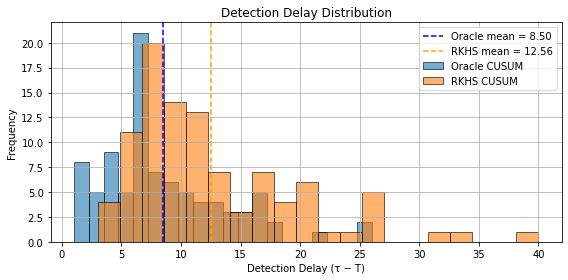

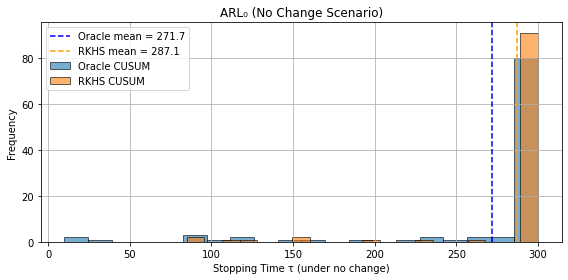

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import sys

sys.path.append('../scripts')
from RKHSbasedCUSUM import RKHSBasedCUSUM

# Oracle CUSUM class for comparison
class OracleCUSUM:
    def __init__(self, f0_pdf, f1_pdf, threshold):
        self.f0 = f0_pdf
        self.f1 = f1_pdf
        self.threshold = threshold

    def run(self, stream):
        W = np.zeros(len(stream))
        tau = None
        for n in range(1, len(stream)):
            llr = np.log(self.f1(stream[n]) / self.f0(stream[n]))
            W[n] = max(0, W[n - 1] + llr)
            if tau is None and W[n] >= self.threshold:
                tau = n
        return W, tau

# Evaluation function
def compare_detectors(
    n_trials=100, n_total=300, changepoint=50,
    threshold=5.0, train_size=300, sigma=1.0, lambda_reg=1e-2
):
    delays_oracle = []
    delays_rkhs = []
    arl0_oracle = []
    arl0_rkhs = []

    f0_pdf = lambda x: norm.pdf(x, loc=0.0, scale=1.0)
    f1_pdf = lambda x: norm.pdf(x, loc=1.0, scale=1.0)

    for seed in range(n_trials):
        np.random.seed(seed)

        # Train RKHS estimator
        X_p = np.random.normal(1.0, 1.0, train_size)
        X_q = np.random.normal(0.0, 1.0, train_size)
        rkhs_model = RKHSBasedCUSUM(threshold=threshold, sigma=sigma, lambda_reg=lambda_reg)
        rkhs_model.fit(X_p, X_q)

        # Run both on a post-change stream
        stream = np.concatenate([
            np.random.normal(0.0, 1.0, changepoint),
            np.random.normal(1.0, 1.0, n_total - changepoint)
        ])
        W_rkhs, tau_rkhs = rkhs_model.run(stream)
        W_oracle, tau_oracle = OracleCUSUM(f0_pdf, f1_pdf, threshold).run(stream)

        if tau_rkhs is not None and tau_rkhs > changepoint:
            delays_rkhs.append(tau_rkhs - changepoint)
        if tau_oracle is not None and tau_oracle > changepoint:
            delays_oracle.append(tau_oracle - changepoint)

        # Run both on no-change stream for ARL
        stream0 = np.random.normal(0.0, 1.0, n_total)
        _, tau_rkhs_0 = rkhs_model.run(stream0)
        _, tau_oracle_0 = OracleCUSUM(f0_pdf, f1_pdf, threshold).run(stream0)
        arl0_rkhs.append(tau_rkhs_0 if tau_rkhs_0 else n_total)
        arl0_oracle.append(tau_oracle_0 if tau_oracle_0 else n_total)

    return {
        "delay_rkhs": delays_rkhs,
        "delay_oracle": delays_oracle,
        "arl0_rkhs": arl0_rkhs,
        "arl0_oracle": arl0_oracle
    }

# Run comparison
metrics = compare_detectors()

# Plot detection delays
plt.figure(figsize=(8, 4))
plt.hist(metrics["delay_oracle"], bins=20, alpha=0.6, label="Oracle CUSUM", edgecolor='black')
plt.hist(metrics["delay_rkhs"], bins=20, alpha=0.6, label="RKHS CUSUM", edgecolor='black')
plt.axvline(np.mean(metrics["delay_oracle"]), color='blue', linestyle='--', label=f'Oracle mean = {np.mean(metrics["delay_oracle"]):.2f}')
plt.axvline(np.mean(metrics["delay_rkhs"]), color='orange', linestyle='--', label=f'RKHS mean = {np.mean(metrics["delay_rkhs"]):.2f}')
plt.xlabel("Detection Delay (τ − T)")
plt.ylabel("Frequency")
plt.title("Detection Delay Distribution")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot ARL0
plt.figure(figsize=(8, 4))
plt.hist(metrics["arl0_oracle"], bins=20, alpha=0.6, label="Oracle CUSUM", edgecolor='black')
plt.hist(metrics["arl0_rkhs"], bins=20, alpha=0.6, label="RKHS CUSUM", edgecolor='black')
plt.axvline(np.mean(metrics["arl0_oracle"]), color='blue', linestyle='--', label=f'Oracle mean = {np.mean(metrics["arl0_oracle"]):.1f}')
plt.axvline(np.mean(metrics["arl0_rkhs"]), color='orange', linestyle='--', label=f'RKHS mean = {np.mean(metrics["arl0_rkhs"]):.1f}')
plt.xlabel("Stopping Time τ (under no change)")
plt.ylabel("Frequency")
plt.title("ARL₀ (No Change Scenario)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


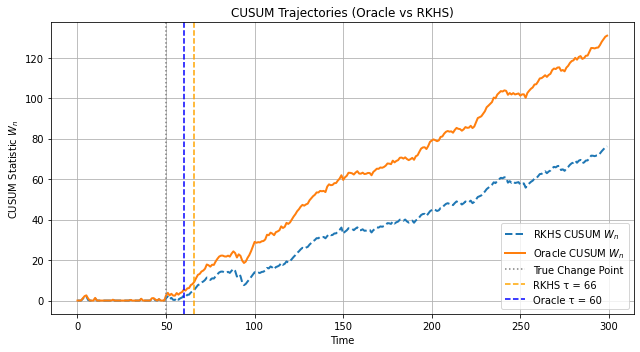

In [3]:
# Plot a single W_n trajectory for both detectors
np.random.seed(4)

# Fit RKHS estimator
X_p = np.random.normal(1.0, 1.0, 300)
X_q = np.random.normal(0.0, 1.0, 300)
rkhs_model = RKHSBasedCUSUM(threshold=5.0)
rkhs_model.fit(X_p, X_q)

# Generate test stream
changepoint = 50
n_total = 300
stream = np.concatenate([
    np.random.normal(0.0, 1.0, changepoint),
    np.random.normal(1.0, 1.0, n_total - changepoint)
])

# Run both detectors
W_rkhs, tau_rkhs = rkhs_model.run(stream)
oracle = OracleCUSUM(f0_pdf=lambda x: norm.pdf(x, 0, 1),
                     f1_pdf=lambda x: norm.pdf(x, 1, 1),
                     threshold=5.0)
W_oracle, tau_oracle = oracle.run(stream)

# Plot trajectories
plt.figure(figsize=(9, 5))
plt.plot(W_rkhs, label="RKHS CUSUM $W_n$", linestyle='--', linewidth=2)
plt.plot(W_oracle, label="Oracle CUSUM $W_n$", linestyle='-', linewidth=2)
plt.axvline(changepoint, color='gray', linestyle=':', label="True Change Point")
if tau_rkhs: plt.axvline(tau_rkhs, color='orange', linestyle='--', label=f"RKHS τ = {tau_rkhs}")
if tau_oracle: plt.axvline(tau_oracle, color='blue', linestyle='--', label=f"Oracle τ = {tau_oracle}")
plt.xlabel("Time")
plt.ylabel("CUSUM Statistic $W_n$")
plt.title("CUSUM Trajectories (Oracle vs RKHS)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()